# 01 — MovieLens Dataset Audit

**Project:** TASTERA  
**Stage:** Data understanding and quality assessment  
**Dataset:** MovieLens Latest Small (ml-latest-small)  
**Status:** Initial local audit completed; follow-up rating-key and scale checks must be run before modeling.

## 1. Objective
Inspect source files before preprocessing or modeling. Check schemas, dimensions, missing values, duplicate records, identifier consistency, rating behavior, user activity, movie popularity, genre coverage, and tag coverage.

## 2. Reproducibility and data handling
- Keep original downloaded CSV files unchanged under data/raw/.
- This notebook reads source data and creates plots/tables in notebook output only; it does not rewrite source CSVs.
- Run cells from top to bottom. Record the Python/package environment when reporting results.
- Review the included dataset README and current GroupLens terms before redistribution or commercial use.

Expected local data directory: data/raw/movielens/ml-latest-small/.

## 3. Imports and paths
Load analysis libraries and locate the dataset whether Jupyter starts in the repository root or notebooks/.

In [29]:
from pathlib import Path
import platform
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 50)
pd.set_option('display.max_colwidth', 100)

candidate_paths = [
    Path('data/raw/movielens/ml-latest-small'),
    Path('../data/raw/movielens/ml-latest-small'),
    Path.cwd() / 'data/raw/movielens/ml-latest-small',
    Path.cwd().parent / 'data/raw/movielens/ml-latest-small',
]
DATA_DIR = next((p.resolve() for p in candidate_paths if (p / 'movies.csv').exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError('Could not find movies.csv. Place files in data/raw/movielens/ml-latest-small/ or update DATA_DIR.')

print('Python:', sys.version.split()[0])
print('Platform:', platform.platform())
print('pandas:', pd.__version__)
print('NumPy:', np.__version__)
print('Dataset directory:', DATA_DIR)

Python: 3.13.3
Platform: Windows-11-10.0.26200-SP0
pandas: 3.0.6
NumPy: 2.5.4
Dataset directory: D:\Tastera\Tastera\data\raw\movielens\ml-latest-small


## 4. Load source files
Load the four CSVs separately and inspect dimensions, columns, data types, and sample records.

In [30]:
file_names = ['movies.csv', 'ratings.csv', 'tags.csv', 'links.csv']
missing_files = [name for name in file_names if not (DATA_DIR / name).exists()]
if missing_files:
    raise FileNotFoundError(f'Missing expected dataset files: {missing_files}')

movies = pd.read_csv(DATA_DIR / 'movies.csv')
ratings = pd.read_csv(DATA_DIR / 'ratings.csv')
tags = pd.read_csv(DATA_DIR / 'tags.csv')
links = pd.read_csv(DATA_DIR / 'links.csv')
datasets = {'movies': movies, 'ratings': ratings, 'tags': tags, 'links': links}

schema_summary = pd.DataFrame([
    {'dataset': name, 'rows': df.shape[0], 'columns': df.shape[1], 'column_names': ', '.join(df.columns)}
    for name, df in datasets.items()
])
display(schema_summary)

for name, df in datasets.items():
    print(f'\n{name.upper()} — first five rows')
    display(df.head())
    print('Data types:')
    display(df.dtypes.rename('dtype').to_frame())

,dataset,rows,columns,column_names
0,movies,9742,3,"movieId, title, genres"
1,ratings,100836,4,"userId, movieId, rating, timestamp"
2,tags,3683,4,"userId, movieId, tag, timestamp"
3,links,9742,3,"movieId, imdbId, tmdbId"



MOVIES — first five rows


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


Data types:


,dtype
movieId,int64
title,str
genres,str


...

,dtype
userId,int64
movieId,int64
tag,str
timestamp,int64



LINKS — first five rows


,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


Data types:


,dtype
movieId,int64
imdbId,int64
tmdbId,float64


## 5. Missing values and duplicate rows
Report missing values and duplicate full rows before deciding whether cleaning is appropriate.

In [31]:
missing_rows = []
for name, df in datasets.items():
    for column in df.columns:
        count = int(df[column].isna().sum())
        missing_rows.append({'dataset': name, 'column': column, 'missing_count': count,
                             'missing_percent': 100 * count / len(df) if len(df) else np.nan})
display(pd.DataFrame(missing_rows))

duplicate_summary = pd.DataFrame([
    {'dataset': name, 'duplicate_full_rows': int(df.duplicated().sum()), 'rows': len(df)}
    for name, df in datasets.items()
])
display(duplicate_summary)

,dataset,column,missing_count,missing_percent
0,movies,movieId,0,0.000000
1,movies,title,0,0.000000
2,movies,genres,0,0.000000
3,ratings,userId,0,0.000000
4,ratings,movieId,0,0.000000
5,ratings,rating,0,0.000000
6,ratings,timestamp,0,0.000000
7,tags,userId,0,0.000000
8,tags,movieId,0,0.000000
9,tags,tag,0,0.000000


,dataset,duplicate_full_rows,rows
0,movies,0,9742
1,ratings,0,100836
2,tags,0,3683
3,links,0,9742


## 6. Identifier consistency
Check expected key uniqueness and whether ratings, tags, and links refer to movie IDs in the catalog. These checks are diagnostic; no records are changed automatically.

In [32]:
movie_ids = set(movies['movieId'].dropna().astype(int))
link_ids = set(links['movieId'].dropna().astype(int))
rating_movie_ids = set(ratings['movieId'].dropna().astype(int))
tag_movie_ids = set(tags['movieId'].dropna().astype(int))

id_checks = pd.DataFrame([
    {'check': 'movies.movieId unique', 'value': bool(movies['movieId'].is_unique)},
    {'check': 'links.movieId unique', 'value': bool(links['movieId'].is_unique)},
    {'check': 'movie IDs missing from links', 'value': len(movie_ids - link_ids)},
    {'check': 'link IDs absent from movies', 'value': len(link_ids - movie_ids)},
    {'check': 'rating movie IDs absent from movies', 'value': len(rating_movie_ids - movie_ids)},
    {'check': 'tag movie IDs absent from movies', 'value': len(tag_movie_ids - movie_ids)},
    {'check': 'ratings userId null count', 'value': int(ratings['userId'].isna().sum())},
    {'check': 'ratings movieId null count', 'value': int(ratings['movieId'].isna().sum())},
])
display(id_checks)
print('Movie IDs in catalog:', len(movie_ids))
print('Movie IDs in links:', len(link_ids))
print('Movie IDs appearing in ratings:', len(rating_movie_ids))
print('Movie IDs appearing in tags:', len(tag_movie_ids))

,check,value
0,movies.movieId unique,True
1,links.movieId unique,True
2,movie IDs missing from links,0
3,link IDs absent from movies,0
4,rating movie IDs absent from movies,0
5,tag movie IDs absent from movies,0
6,ratings userId null count,0
7,ratings movieId null count,0


Movie IDs in catalog: 9742
Movie IDs in links: 9742
Movie IDs appearing in ratings: 9724
Movie IDs appearing in tags: 1572


## 7. Rating distribution and activity
Inspect the rating scale, overall distribution, and how ratings are distributed across users and movies. Ratings are observed feedback, not a complete record of taste.

Rating summary:


,count,mean,std,min,25%,50%,75%,max
rating,100836.0,3.501557,1.042529,0.5,3.0,3.5,4.0,5.0


Observed rating values and counts:


,count
rating,
0.5,1370
1.0,2811
1.5,1791
2.0,7551
2.5,5550
3.0,20047
3.5,13136
4.0,26818
4.5,8551


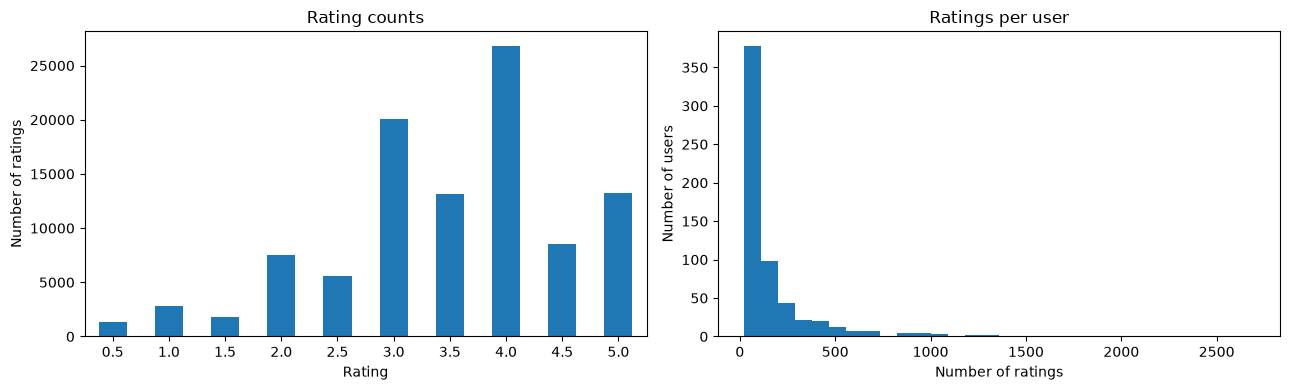

,ratings_per_user,ratings_per_movie
count,610.000000,9724.000000
mean,165.304918,10.369807
std,269.480584,22.401005
min,20.000000,1.000000
25%,35.000000,1.000000
50%,70.500000,3.000000
75%,168.000000,9.000000
max,2698.000000,329.000000


In [33]:
print('Rating summary:')
display(ratings['rating'].describe().to_frame().T)
print('Observed rating values and counts:')
display(ratings['rating'].value_counts(dropna=False).sort_index().rename_axis('rating').to_frame('count'))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ratings['rating'].value_counts().sort_index().plot(kind='bar', ax=axes[0])
axes[0].set_title('Rating counts')
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Number of ratings')
axes[0].tick_params(axis='x', rotation=0)

ratings_per_user = ratings.groupby('userId').size()
ratings_per_movie = ratings.groupby('movieId').size()
ratings_per_user.plot(kind='hist', bins=30, ax=axes[1])
axes[1].set_title('Ratings per user')
axes[1].set_xlabel('Number of ratings')
axes[1].set_ylabel('Number of users')
plt.tight_layout()
plt.show()

display(pd.DataFrame({'ratings_per_user': ratings_per_user.describe(),
                      'ratings_per_movie': ratings_per_movie.describe()}))

## 8. Rating sparsity
A user–movie matrix is sparse because each user rates only a subset of the catalog. Sparsity affects collaborative filtering and cold-start behavior.

In [34]:
n_users = ratings['userId'].nunique()
n_rated_movies = ratings['movieId'].nunique()
n_observed = len(ratings)
possible_pairs = n_users * n_rated_movies
density = n_observed / possible_pairs if possible_pairs else np.nan
sparsity = 1 - density if possible_pairs else np.nan

sparsity_summary = pd.DataFrame([{
    'unique_users': n_users,
    'unique_rated_movies': n_rated_movies,
    'observed_ratings': n_observed,
    'possible_user_movie_pairs_for_rated_catalog': possible_pairs,
    'observed_density_percent': density * 100,
    'sparsity_percent': sparsity * 100,
}])
display(sparsity_summary)

,unique_users,unique_rated_movies,observed_ratings,possible_user_movie_pairs_for_rated_catalog,observed_density_percent,sparsity_percent
0,610,9724,100836,5931640,1.699968,98.300032


## 9. Genre coverage and frequency
Genres are pipe-separated labels. Split them for descriptive analysis while leaving movies.csv unchanged.

,movie_count
genre,
Drama,4361
Comedy,3756
Thriller,1894
Action,1828
Romance,1596
Adventure,1263
Crime,1199
Sci-Fi,980
Horror,978


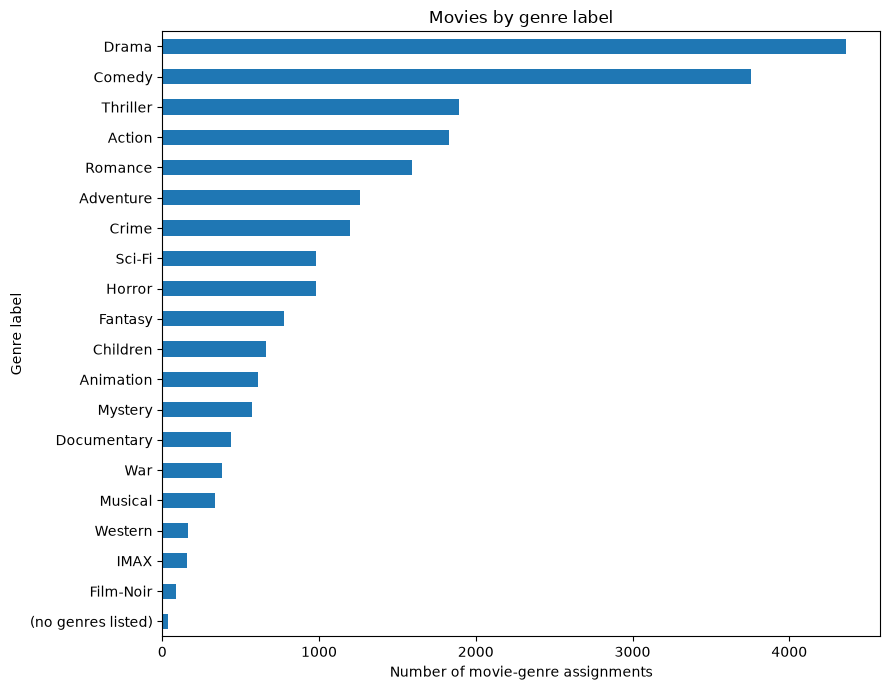

In [35]:
genre_counts = (movies['genres'].fillna('').str.split('|').explode().str.strip()
                .replace('', np.nan).dropna().value_counts())
display(genre_counts.rename_axis('genre').to_frame('movie_count'))
genre_counts.sort_values().plot(kind='barh', figsize=(9, 7))
plt.title('Movies by genre label')
plt.xlabel('Number of movie-genre assignments')
plt.ylabel('Genre label')
plt.tight_layout()
plt.show()

## 10. Tags and external identifiers
Tags can enrich content features. IMDb/TMDB identifiers may help match metadata, but coverage must be checked first.

In [36]:
print('Tag rows:', len(tags))
print('Unique tags (case-sensitive):', tags['tag'].nunique(dropna=True))
print('Unique users who supplied tags:', tags['userId'].nunique())
print('Unique movies with tags:', tags['movieId'].nunique())
display(tags['tag'].value_counts().head(20).rename_axis('tag').to_frame('count'))

link_coverage = pd.DataFrame([
    {'identifier': 'imdbId', 'non_null_count': int(links['imdbId'].notna().sum()), 'total_rows': len(links)},
    {'identifier': 'tmdbId', 'non_null_count': int(links['tmdbId'].notna().sum()), 'total_rows': len(links)},
])
link_coverage['coverage_percent'] = 100 * link_coverage['non_null_count'] / link_coverage['total_rows']
display(link_coverage)

Tag rows: 3683
Unique tags (case-sensitive): 1589
Unique users who supplied tags: 58
Unique movies with tags: 1572


,count
tag,
In Netflix queue,131
atmospheric,36
superhero,24
thought-provoking,24
funny,23
Disney,23
surreal,23
religion,22
sci-fi,21


,identifier,non_null_count,total_rows,coverage_percent
0,imdbId,9742,9742,100.000000
1,tmdbId,9734,9742,99.917881


## 11. Timestamp coverage
Timestamps are Unix seconds in this dataset. Convert them to UTC for summaries; do not interpret them as a user's local time without an explicit timezone decision.

In [37]:
for name, df in [('ratings', ratings), ('tags', tags)]:
    if 'timestamp' in df.columns and df['timestamp'].notna().any():
        timestamp_utc = pd.to_datetime(df['timestamp'], unit='s', utc=True, errors='coerce')
        print(f'{name}: {timestamp_utc.min()} to {timestamp_utc.max()} (UTC)')
    else:
        print(f'{name}: no usable timestamps found')

ratings: 1996-03-29 18:36:55+00:00 to 2018-09-24 14:27:30+00:00 (UTC)
tags: 2006-01-13 19:09:12+00:00 to 2018-09-16 11:50:03+00:00 (UTC)


In [38]:
# Follow-up validation: repeated user/movie ratings and rating scale
duplicate_user_movie_pairs = ratings.duplicated(subset=['userId', 'movieId'], keep=False)
print('Duplicate (userId, movieId) pairs:', int(duplicate_user_movie_pairs.sum()))
print('Rows participating in duplicate pairs:', int(duplicate_user_movie_pairs.sum()))

expected_rating_values = {0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0}
observed_rating_values = set(ratings['rating'].dropna().unique().tolist())
unexpected_rating_values = sorted(observed_rating_values - expected_rating_values)
missing_rating_count = int(ratings['rating'].isna().sum())
print('Observed rating values:', sorted(observed_rating_values))
print('Unexpected rating values outside the expected half-star scale:', unexpected_rating_values)
print('Missing rating values:', missing_rating_count)

rating_validation = pd.DataFrame([{
    'duplicate_user_movie_pairs': int(ratings.duplicated(subset=['userId', 'movieId']).sum()),
    'unexpected_rating_values': unexpected_rating_values,
    'missing_ratings': missing_rating_count,
    'minimum_rating': float(ratings['rating'].min()),
    'maximum_rating': float(ratings['rating'].max()),
}])
display(rating_validation)

Duplicate (userId, movieId) pairs: 0
Rows participating in duplicate pairs: 0
Observed rating values: [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
Unexpected rating values outside the expected half-star scale: []
Missing rating values: 0


,duplicate_user_movie_pairs,unexpected_rating_values,missing_ratings,minimum_rating,maximum_rating
0,0,[],0,0.5,5.0


## 12. Findings and decisions

These findings were recorded from a successful local run of this notebook on the MovieLens Latest Small files. Re-run the notebook against the current local files before relying on these figures in a later experiment.

### Findings

- The four source files contain 9,742 movies, 100,836 ratings, 3,683 tag records, and 9,742 link rows.
- No missing values were observed in the inspected `movies.csv`, `ratings.csv`, or `tags.csv` fields. Eight `links.tmdbId` values are missing (0.0821%); `imdbId` coverage is 100%.
- No duplicate full rows were observed in any of the four files.
- Movie IDs are unique in the movie catalog and links table. No rating or tag movie IDs were found outside the movie catalog.
- Ratings have mean 3.5016, median 3.5, standard deviation 1.0425, and observed minimum/maximum of 0.5 and 5.0. Ratings are recorded in half-star increments.
- The 610 users contributed 100,836 ratings across 9,724 distinct movies. Ratings per user average 165.30 (median 70.5); ratings per rated movie average 10.37 (median 3).
- The user–movie matrix for 610 users and 9,724 rated movies has 5,931,640 possible pairs. The observed density is 1.7000%, so sparsity is 98.3000%.
- Drama (4,361 titles) and Comedy (3,756) are the most common genres. Thirty-four movies have no genre listed.
- The tag file has 3,683 rows, 1,589 case-sensitive unique tag strings, 58 tag contributors, and tags for 1,572 distinct movies.
- Rating timestamps span 1996-03-29 18:36:55 UTC to 2018-09-24 14:27:30 UTC. Tag timestamps span 2006-01-13 19:09:12 UTC to 2018-09-16 11:50:03 UTC.

### Modeling implications

- Start content-based experiments with genres and title text; treat tags as an optional signal because they cover only a subset of the catalog.
- Keep movies with missing TMDB IDs in the catalog; missing external metadata IDs are not missing movie records.
- Compare popularity and content-based baselines with a collaborative-filtering model. Report cold-start and catalog-coverage limitations.
- Use a deliberate split strategy and fit learned preprocessing only on training data. Do not use a random split by default for a time-sensitive evaluation.

### Follow-up validation still required

- The audit currently checks duplicate full rows, but a separate check for duplicate `(userId, movieId)` rating pairs and the expected rating scale is added in the next cell. Run it and review the printed results before finalizing cleaning decisions.
- These data describe a particular research dataset and should not be treated as representative of all viewers.
- Review dataset terms and external metadata licensing before public or commercial deployment.

### Next steps

1. Run the follow-up key and rating-scale validation cell.
2. Document the baseline comparison and evaluation split in `docs/experiments/02-baseline-recommenders.md`.
3. Keep the raw source files unchanged and document any later transformations.
